        # Cognitive Science (1204 427) — Lab 06
        ## Risky Choice and Prospect Theory

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib`

        ### แนวคิดสำคัญ

        Prospect Theory เสนอว่ามนุษย์ประเมินกำไรและขาดทุนแบบไม่สมมาตร โดย Loss Aversion ทำให้การขาดทุนมีน้ำหนักมากกว่ากำไรขนาดเท่ากัน

        ### วัตถุประสงค์

        เปรียบเทียบ Expected Value กับ Subjective Value ประมาณค่าพารามิเตอร์ Loss Aversion และอธิบาย Risk Preference ภายใต้ Gain/Loss Frames

        ### งานที่ต้องทำ

        1. คำนวณ Expected Value ของ Sure และ Gamble Options
2. สร้าง Choice Data ของผู้เข้าร่วมหลายคน
3. คำนวณ Prospect Value
4. ประมาณค่า Loss-aversion parameter ด้วย Grid Search
5. Required Extension: วิเคราะห์ผลเมื่อ alpha เปลี่ยน

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed + 60)
gambles = pd.DataFrame([
    [1, "Gain", 40, 0, 100, 0.40],
    [2, "Gain", 50, 0, 120, 0.42],
    [3, "Gain", 60, 0, 150, 0.40],
    [4, "Loss", -40, 0, -100, 0.40],
    [5, "Loss", -50, 0, -120, 0.42],
    [6, "Loss", -60, 0, -150, 0.40],
    [7, "Mixed", 0, -25, 60, 0.50],
    [8, "Mixed", 0, -40, 90, 0.50],
    [9, "Mixed", 0, -55, 120, 0.50],
    [10, "Mixed", 0, -70, 150, 0.50],
    [11, "Mixed", 0, -35, 70, 0.55],
    [12, "Mixed", 0, -60, 140, 0.45],
], columns=["trial_type", "frame", "sure", "gamble_low", "gamble_high", "p_high"])
gambles["ev_sure"] = gambles["sure"]
gambles["ev_gamble"] = gambles["p_high"] * gambles["gamble_high"] + (1 - gambles["p_high"]) * gambles["gamble_low"]
display(gambles)


,trial_type,frame,sure,gamble_low,gamble_high,p_high,ev_sure,ev_gamble
0,1,Gain,40,0,100,0.40,40,40.00
1,2,Gain,50,0,120,0.42,50,50.40
2,3,Gain,60,0,150,0.40,60,60.00
3,4,Loss,-40,0,-100,0.40,-40,-40.00
4,5,Loss,-50,0,-120,0.42,-50,-50.40
5,6,Loss,-60,0,-150,0.40,-60,-60.00
6,7,Mixed,0,-25,60,0.50,0,17.50
7,8,Mixed,0,-40,90,0.50,0,25.00
8,9,Mixed,0,-55,120,0.50,0,32.50
9,10,Mixed,0,-70,150,0.50,0,40.00


In [3]:
def value(x, alpha=0.88, loss_lambda=2.25):
    if np.isscalar(x):
        return x ** alpha if x >= 0 else -loss_lambda * ((-x) ** alpha)
    x = np.asarray(x, dtype=float)
    result = np.empty_like(x)
    positive = x >= 0
    result[positive] = x[positive] ** alpha
    result[~positive] = -loss_lambda * ((-x[~positive]) ** alpha)
    return result

def prospect_difference(row, alpha, loss_lambda):
    sure_v = value(row.sure, alpha, loss_lambda)
    gamble_v = row.p_high * value(row.gamble_high, alpha, loss_lambda) + (1 - row.p_high) * value(row.gamble_low, alpha, loss_lambda)
    return float(gamble_v - sure_v)

true_lambda = rng.uniform(1.8, 2.8)
beta = 0.10
rows = []
for participant in range(1, 41):
    for row in gambles.itertuples():
        dv = prospect_difference(row, 0.88, true_lambda)
        p_gamble = 1 / (1 + np.exp(-beta * dv))
        chose_gamble = rng.binomial(1, p_gamble)
        rows.append([participant, row.trial_type, row.frame, chose_gamble])
choice_df = pd.DataFrame(rows, columns=["participant", "trial_type", "frame", "chose_gamble"])
display(choice_df.groupby("frame")["chose_gamble"].mean().rename("gamble_rate"))


frame
Gain     0.4250
Loss     0.6500
Mixed    0.4125
Name: gamble_rate, dtype: float64

True simulation lambda=2.256
Best grid-search lambda=2.050


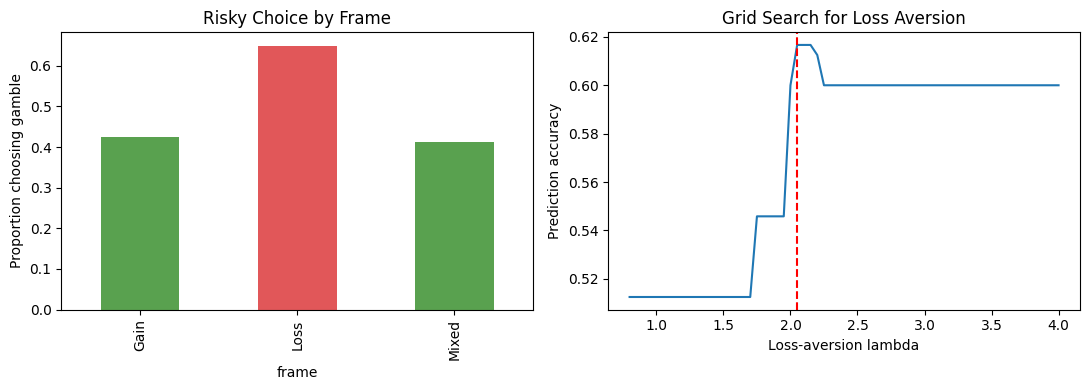

In [4]:
# Grid Search: เลือก lambda ที่ทำนาย Choice ได้แม่นที่สุด
candidates = np.linspace(0.8, 4.0, 65)
scores = []
merged = choice_df.merge(gambles, on=["trial_type", "frame"])
for candidate in candidates:
    predictions = []
    for row in merged.itertuples():
        predictions.append(int(prospect_difference(row, 0.88, candidate) > 0))
    scores.append(np.mean(np.array(predictions) == merged["chose_gamble"].to_numpy()))
best_lambda = candidates[int(np.argmax(scores))]
print(f"True simulation lambda={true_lambda:.3f}")
print(f"Best grid-search lambda={best_lambda:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
choice_df.groupby("frame")["chose_gamble"].mean().plot(kind="bar", ax=axes[0], color=["#59a14f", "#e15759"])
axes[0].set_ylabel("Proportion choosing gamble"); axes[0].set_title("Risky Choice by Frame")
axes[1].plot(candidates, scores); axes[1].axvline(best_lambda, color="red", linestyle="--")
axes[1].set_xlabel("Loss-aversion lambda"); axes[1].set_ylabel("Prediction accuracy")
axes[1].set_title("Grid Search for Loss Aversion")
plt.tight_layout(); plt.show()


## Required Extension

ทำ Grid Search ซ้ำเมื่อ `alpha` เท่ากับ 0.70, 0.88 และ 1.00 แล้วสร้างตารางเปรียบเทียบ Best Lambda และ Prediction Accuracy


,alpha,best_lambda,prediction_accuracy
0,0.70,1.80,0.617
1,0.88,2.05,0.617
2,1.00,3.65,0.538


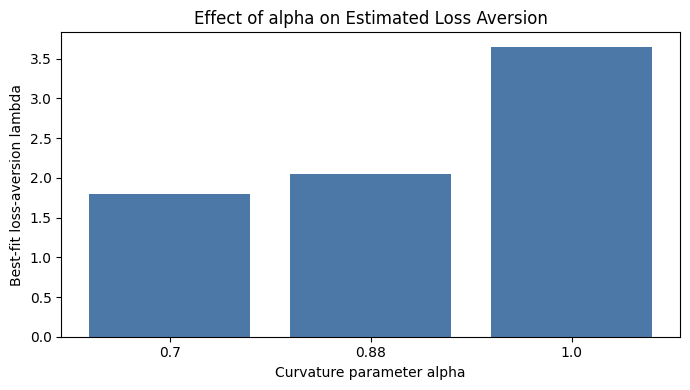

lambda จริงที่ใช้จำลอง = 2.256


In [5]:
# ===== Required Extension: เปรียบเทียบ Grid Search เมื่อ alpha ต่างกัน =====
alpha_rows = []
for alpha in [0.70, 0.88, 1.00]:
    accs = []
    for candidate in candidates:
        preds = [int(prospect_difference(r, alpha, candidate) > 0) for r in merged.itertuples()]
        accs.append(np.mean(np.array(preds) == merged["chose_gamble"].to_numpy()))
    best_l = candidates[int(np.argmax(accs))]
    alpha_rows.append([alpha, best_l, max(accs)])

alpha_df = pd.DataFrame(alpha_rows, columns=["alpha", "best_lambda", "prediction_accuracy"])
display(alpha_df.round(3))

plt.figure(figsize=(7, 4))
plt.bar(alpha_df["alpha"].astype(str), alpha_df["best_lambda"], color="#4c78a8")
plt.xlabel("Curvature parameter alpha")
plt.ylabel("Best-fit loss-aversion lambda")
plt.title("Effect of alpha on Estimated Loss Aversion")
plt.tight_layout()
plt.show()
print(f"lambda จริงที่ใช้จำลอง = {true_lambda:.3f}")


## คำถามวิเคราะห์ Lab 06

**1. Expected Value กับ Prospect Value ต่างกันอย่างไร**

EV คือค่าเฉลี่ยตามความน่าจะเป็นตรงๆ (objective) ส่วน Prospect Value เอาค่ามาผ่าน value function ที่โค้ง (alpha) และคูณ loss aversion (lambda) กับฝั่งขาดทุน เลยสะท้อนว่าคน "รู้สึก" กับเงินไม่เป็นเส้นตรงและกลัวเสียมากกว่าดีใจตอนได้

**2. Gain และ Loss Frames ทำให้ Gamble Rate ต่างกันหรือไม่**

ต่างครับ ฝั่ง Loss คนเลือกเสี่ยง (gamble) มากกว่า (~0.65) เทียบกับฝั่ง Gain (~0.43) ตรงกับ prospect theory ที่ว่าคน risk-averse ตอนได้ แต่ risk-seeking ตอนจะเสีย (ยอมเสี่ยงเพื่อหนีการขาดทุนที่แน่นอน)

**3. Best Lambda ที่ได้ใกล้ค่าจริงเพียงใด และเหตุใดอาจคลาดเคลื่อน**

ค่อนข้างใกล้ครับ best lambda ≈ 2.05 เทียบกับค่าจริง ≈ 2.26 คลาดนิดหน่อยเพราะ choice เป็นข้อมูล binary ที่มี noise จาก softmax, จำนวน trial/คนจำกัด และ grid หยาบ (ทีละช่วง) เลยได้ค่าประมาณที่ไม่เป๊ะ

**4. Alpha และ Lambda มีบทบาทต่างกันอย่างไร**

alpha คุมความโค้งของ value function (ความรู้สึกที่ลดหลั่นเมื่อเงินมากขึ้น เท่ากันทั้งได้และเสีย) ส่วน lambda คุมเฉพาะว่าฝั่งขาดทุนถูกขยายกี่เท่า (loss aversion) คนละหน้าที่กัน จาก extension จะเห็นว่าพอ alpha เปลี่ยน ค่า best lambda ที่ fit ได้ก็ขยับตามด้วย

**5. Prospect Theory อธิบายพฤติกรรมใดได้ดีกว่า Expected Utility แบบง่าย**

อธิบาย framing effect และการที่คนเลือกต่างกันระหว่างกรอบ gain/loss ทั้งที่ EV เท่ากัน รวมถึง loss aversion และการยอมเสี่ยงเพื่อเลี่ยงการขาดทุน ซึ่ง expected utility แบบเส้นตรงอธิบายไม่ได้

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือทำความเข้าใจ value function กับ grid search ตอนแรกงงว่า alpha กับ lambda ต่างกันยังไง พอลองทำ extension เปลี่ยน alpha สามค่าแล้วเห็นว่า best lambda ขยับตาม ถึงเข้าใจว่าสองตัวนี้มันพันกันในการ fit

สิ่งที่เชื่อมกับ cognitive science คือมันอธิบายได้ว่าทำไมคนถึงกลัวเสียมากกว่าดีใจตอนได้ และทำไมแค่เปลี่ยนกรอบเป็น gain/loss คนก็เลือกเสี่ยงไม่เท่ากัน เห็น loss aversion เป็นตัวเลข (lambda ~2) ชัดดี

ถ้าทำซ้ำ อยากใช้ grid ที่ละเอียดขึ้นหรือ optimizer จริงแทน grid หยาบ และ fit ทั้ง alpha กับ lambda พร้อมกันแทนที่จะ fix alpha รวมถึงเพิ่มจำนวน trial ต่อคนเพื่อให้ค่าประมาณแม่นขึ้น

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
